# IT support ticket classification and priority rules

A new ticket arrives and only its text is known at that moment. This notebook predicts the ticket category from that text with a machine learning model, and assigns a priority with a transparent rule layer.

**Why priority uses rules.** This dataset has no priority column. A model trained on priorities that we invent from rules would only learn those rules, so any accuracy it reported would be circular. The priority layer is therefore presented as rules, not as a learned model, and it is checked by reading examples rather than by an accuracy score.

**Changes in version 3.** Confidence values are now calibrated with temperature scaling, which keeps the model predictions exactly as they were and only rescales the scores. The priority rules were revised after the rule audit of version 2: the routine request rule was narrowed, the word server was removed from wide impact, broken devices now score less than outages, and scheduled notices lose more points. The human review sample no longer depends on the rules or the model, so your labels stay valid when the rules change. The notebook also writes a run summary file with the key numbers.

**Running locally or on Kaggle.** The notebook finds its data and writes its outputs in both places. The GPU only affects XGBoost. The scikit learn models run on the CPU, so a GPU session is optional. Scores can differ slightly between GPU and CPU runs, and the numbers to report are the ones from the run saved in the outputs.

## Section 1. Setup

All imports sit in one cell. Nothing is installed by this notebook. The packages used are pandas, numpy, matplotlib, seaborn, scikit learn, xgboost and joblib.

In [59]:
import json
import os
import re
import shutil
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', module='xgboost')

### Settings and environment

One place holds every setting. `CV_MAX_ROWS` limits how many training rows are used for the model comparison and tuning, which keeps the run time reasonable on a large dataset. The final model is always refit on the full training set. Outputs go into a subfolder named after the dataset, so earlier results are never overwritten.

In [60]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_JOBS = max(1, os.cpu_count() or 1)
CV_SPLITS = 5
CV_MAX_ROWS = 20000
TEST_SIZE = 0.20
MAX_FEATURES = 20000
DATASET_TAG = 'it_tickets'
DATA_PATH_OVERRIDE = None
STOP_WORDS = 'english'

ON_KAGGLE = Path('/kaggle/input').exists()
if ON_KAGGLE:
    BASE_DIR = Path('/kaggle/working')
else:
    cwd = Path.cwd()
    BASE_DIR = cwd.parent if cwd.name == 'notebooks' else cwd
OUT_DIR = BASE_DIR / 'outputs' / DATASET_TAG
IMG_DIR = BASE_DIR / 'docs' / 'images' / DATASET_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)

def gpu_available():
    # Newer XGBoost versions silently fall back to the CPU when no GPU exists,
    # so a real GPU is confirmed first, then a tiny XGBoost fit on it is tried.
    if shutil.which('nvidia-smi') is None:
        return False
    try:
        probe = XGBClassifier(n_estimators=2, max_depth=2, device='cuda', tree_method='hist')
        probe.fit(np.random.rand(40, 4), np.array([0, 1] * 20))
        return True
    except Exception:
        return False

USE_GPU = gpu_available()
XGB_DEVICE = 'cuda' if USE_GPU else 'cpu'

VERSIONS = {
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'scikit_learn': sklearn.__version__,
    'xgboost': xgboost.__version__,
}
print(f'Environment: {"Kaggle" if ON_KAGGLE else "local"}')
print(f'Base folder: {BASE_DIR}')
print(f'CPU cores used by models: {N_JOBS}')
print(f'XGBoost device: {XGB_DEVICE}')
print(f'Library versions: {VERSIONS}')

def save_fig(filename):
    plt.tight_layout()
    plt.savefig(IMG_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()

Environment: Kaggle
Base folder: /kaggle/working
CPU cores used by models: 4
XGBoost device: cuda
Library versions: {'python': '3.13.16', 'pandas': '2.3.3', 'numpy': '2.1.3', 'scikit_learn': '1.6.1', 'xgboost': '3.4.1'}


## Section 2. Load and inspect

The data file is searched in the Kaggle input folder first, then in a local `raw_data` folder. The ticket text column and the category column are detected from the column names. This dataset is expected to use `Document` for the text and `Topic_group` for the category. If the names differ, the notebook falls back to a simple rule and prints what it chose, so check that printout.

In [61]:
def find_data_file():
    if DATA_PATH_OVERRIDE:
        return Path(DATA_PATH_OVERRIDE)
    roots = []
    if Path('/kaggle/input').exists():
        roots.append(Path('/kaggle/input'))
    roots += [Path.cwd() / 'raw_data', Path.cwd().parent / 'raw_data']
    files = []
    for root in roots:
        if root.exists():
            files += sorted(root.rglob('*.csv'))
    if not files:
        raise FileNotFoundError('No CSV file found in the Kaggle input folder or a local raw_data folder.')
    for file in files:
        try:
            columns = pd.read_csv(file, nrows=0).columns
        except Exception:
            continue
        if {'Document', 'Topic_group'}.issubset(columns):
            return file
    return files[0]

def detect_columns(frame):
    if {'Document', 'Topic_group'}.issubset(frame.columns):
        return 'Document', 'Topic_group'
    print('Expected column names not found. Using an automatic rule, please check the choice below.')
    text_like = [c for c in frame.columns if frame[c].dtype == object]
    if len(text_like) < 2:
        raise KeyError('Could not find a text column and a label column.')
    text_column = max(text_like, key=lambda c: frame[c].astype(str).str.len().mean())
    label_options = [c for c in text_like if c != text_column and frame[c].nunique() <= 50]
    if not label_options:
        raise KeyError('Could not find a label column with a small number of classes.')
    return text_column, min(label_options, key=lambda c: frame[c].nunique())

data_path = find_data_file()
raw = pd.read_csv(data_path)
print(f'Data file: {data_path}')
print(f'Shape: {raw.shape}')
print(f'Columns: {raw.columns.tolist()}')
print('Missing values per column:')
print(raw.isna().sum())
display(raw.head(3))

text_column, label_column = detect_columns(raw)
print(f'Text column: {text_column}')
print(f'Category column: {label_column}')

df = raw[[text_column, label_column]].copy()
df.columns = ['text', 'label']
rows_before = len(df)
df = df.dropna().reset_index(drop=True)
df['text'] = df['text'].astype(str)
df['label'] = df['label'].astype(str).str.strip()
print(f'Rows dropped for missing text or label: {rows_before - len(df)}')

Data file: /kaggle/input/datasets/cyrusndungungugi/all-tickets-processed/all_tickets_processed_improved_v3.csv
Shape: (47837, 2)
Columns: ['Document', 'Topic_group']
Missing values per column:
Document       0
Topic_group    0
dtype: int64


,Document,Topic_group
0,connection with icon icon dear please setup icon per icon engineers please let other details needed thanks...,Hardware
1,work experience user work experience user hi work experience student coming next his name much appreciate ...,Access
2,requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug,Hardware


Text column: Document
Category column: Topic_group
Rows dropped for missing text or label: 0


## Section 3. Target EDA

Class counts show how balanced the categories are. They also set the bar a real model must beat: with imbalanced classes, always predicting the biggest class already earns a decent accuracy, so accuracy alone can mislead and macro F1 is used as the main metric.

,count,percentage
label,,
Hardware,13617,28.47
HR Support,10915,22.82
Access,7125,14.89
Miscellaneous,7060,14.76
Storage,2777,5.81
Purchase,2464,5.15
Internal Project,2119,4.43
Administrative rights,1760,3.68


Number of categories: 8
Imbalance ratio (largest class over smallest): 7.74
Accuracy of always predicting the largest class: 0.285
Chance level macro F1 for a random guess: about 0.125


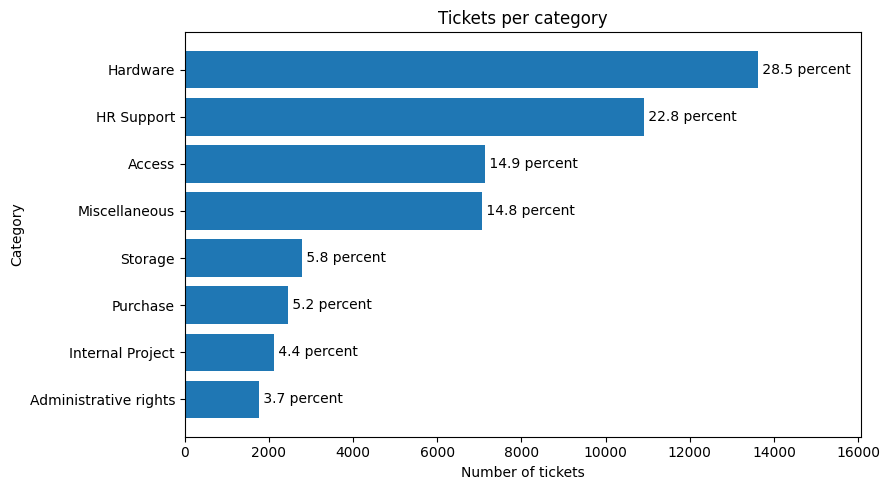

In [62]:
label_counts = df['label'].value_counts()
label_summary = pd.DataFrame({
    'count': label_counts,
    'percentage': (label_counts / label_counts.sum() * 100).round(2),
})
display(label_summary)

n_classes = df['label'].nunique()
imbalance_ratio = label_counts.max() / label_counts.min()
majority_share = label_counts.max() / label_counts.sum()
chance_macro_f1 = 1 / n_classes
print(f'Number of categories: {n_classes}')
print(f'Imbalance ratio (largest class over smallest): {imbalance_ratio:.2f}')
print(f'Accuracy of always predicting the largest class: {majority_share:.3f}')
print(f'Chance level macro F1 for a random guess: about {chance_macro_f1:.3f}')

plt.figure(figsize=(9, 5))
ordered = label_counts.sort_values()
plt.barh(ordered.index, ordered.values)
for position, value in enumerate(ordered.values):
    plt.text(value, position, f' {value / ordered.sum() * 100:.1f} percent', va='center')
plt.title('Tickets per category')
plt.xlabel('Number of tickets')
plt.ylabel('Category')
plt.xlim(0, ordered.max() * 1.18)
save_fig('eda_category_counts.png')

## Section 4. Text cleaning

Cleaning makes the same idea look the same: lowercase, remove web links and tags, replace punctuation with spaces, collapse extra spaces. Stop words are removed later by the vectorizer, not here. Duplicates and common terms in the next section are measured on the cleaned text. If the dataset text was already cleaned by its authors, this step changes very little, and the before and after examples show that.

In [63]:
def clean_text(value):
    text = '' if pd.isna(value) else str(value).lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['clean_text'] = df['text'].map(clean_text)
empty_after_cleaning = int((df['clean_text'] == '').sum())
df = df[df['clean_text'] != ''].reset_index(drop=True)
print(f'Rows removed because the text was empty after cleaning: {empty_after_cleaning}')
print(f'Rows kept: {len(df)}')

pd.set_option('display.max_colwidth', 110)
display(df[['text', 'clean_text']].sample(3, random_state=RANDOM_STATE))

Rows removed because the text was empty after cleaning: 0
Rows kept: 47837


,text,clean_text
41946,issue with server process sent tuesday issue with server process hi could you please help with following i...,issue with server process sent tuesday issue with server process hi could you please help with following i...
20882,new purchase po wednesday february purchase po dear purchased please log installation please take consider...,new purchase po wednesday february purchase po dear purchased please log installation please take consider...
37017,oracle pas urgent re we updated rights query hi can get some assistance here looks like have full control ...,oracle pas urgent re we updated rights query hi can get some assistance here looks like have full control ...


## Section 5. Feature EDA

Three questions about the text. How long are tickets? Are there duplicate tickets, and do they carry conflicting labels? Which terms are common in each category, and which terms are distinctive of a category? Distinctive terms are the ones that appear in a category much more often than in the dataset overall, and they are the real signal a model can use.

       word_count  char_count
count     47837.0     47837.0
mean         43.6       291.9
std          56.7       388.2
min           2.0         7.0
25%          17.0       110.0
50%          26.0       175.0
75%          46.0       304.0
max         981.0      7015.0


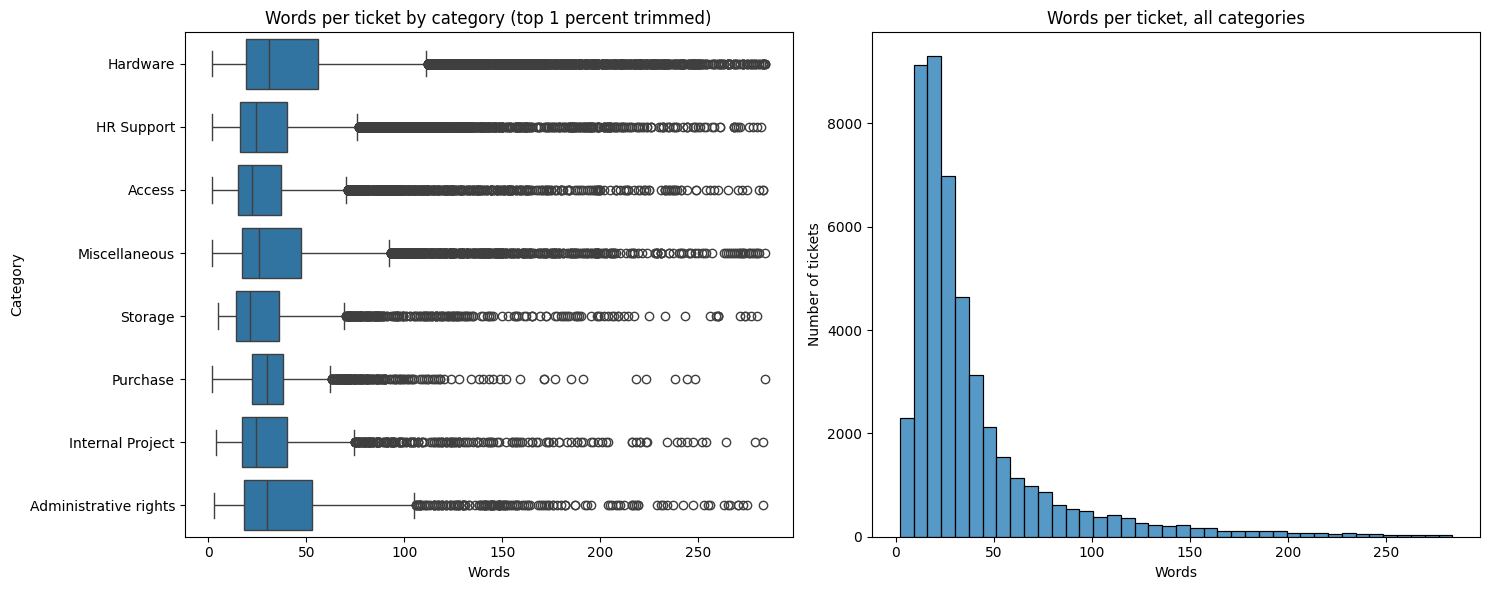

In [64]:
df['word_count'] = df['clean_text'].str.split().str.len()
df['char_count'] = df['clean_text'].str.len()
print(df[['word_count', 'char_count']].describe().round(1))

limit = df['word_count'].quantile(0.99)
trimmed = df[df['word_count'] <= limit]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=trimmed, y='label', x='word_count', order=label_counts.index, ax=axes[0])
axes[0].set_title('Words per ticket by category (top 1 percent trimmed)')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Category')
sns.histplot(trimmed['word_count'], bins=40, ax=axes[1])
axes[1].set_title('Words per ticket, all categories')
axes[1].set_xlabel('Words')
axes[1].set_ylabel('Number of tickets')
save_fig('eda_text_length.png')

In [65]:
unique_texts = df['clean_text'].nunique()
rows_in_duplicate_groups = int(df['clean_text'].duplicated(keep=False).sum())
group_sizes = df.groupby('clean_text').size()
duplicate_groups = int((group_sizes > 1).sum())
labels_per_text = df.groupby('clean_text')['label'].nunique()
conflicting_groups = int((labels_per_text > 1).sum())
print(f'Unique cleaned texts: {unique_texts} of {len(df)} tickets')
print(f'Tickets that share their text with another ticket: {rows_in_duplicate_groups}')
print(f'Groups of identical text: {duplicate_groups}')
print(f'Groups of identical text with conflicting category labels: {conflicting_groups}')
print('Identical texts are kept together in one side of the train and test split, so a model is never tested on a ticket it has seen.')

Unique cleaned texts: 47837 of 47837 tickets
Tickets that share their text with another ticket: 0
Groups of identical text: 0
Groups of identical text with conflicting category labels: 0
Identical texts are kept together in one side of the train and test split, so a model is never tested on a ticket it has seen.


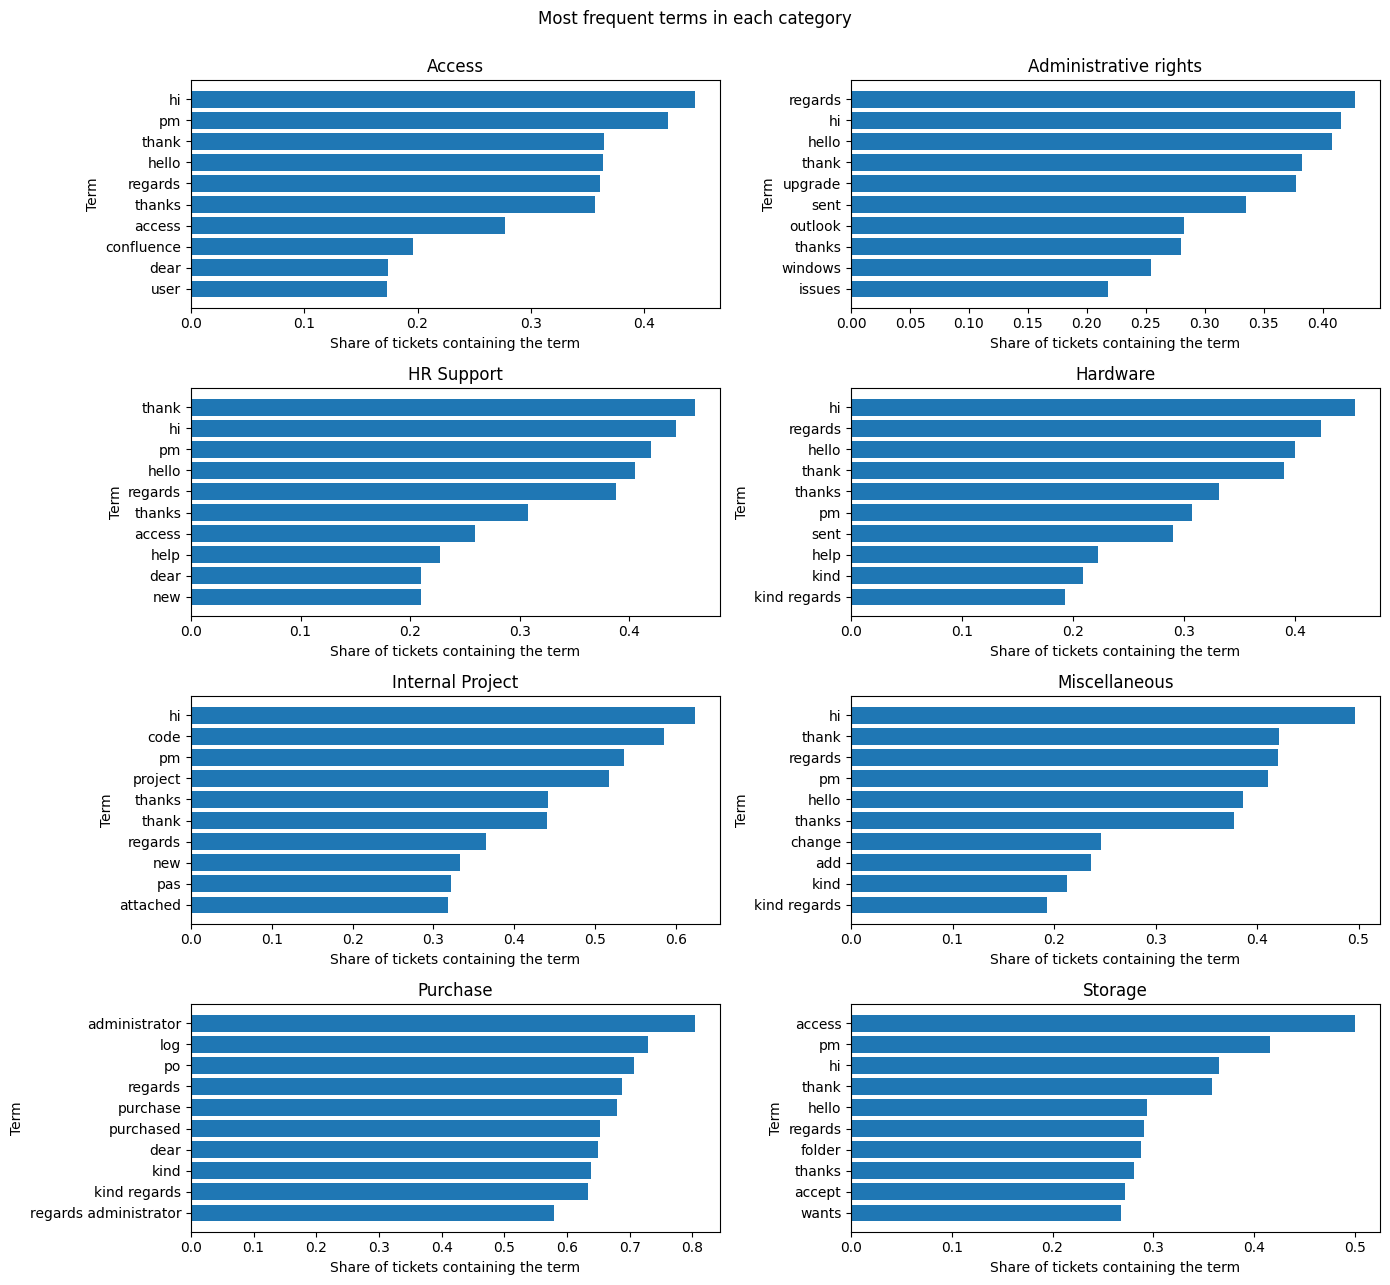

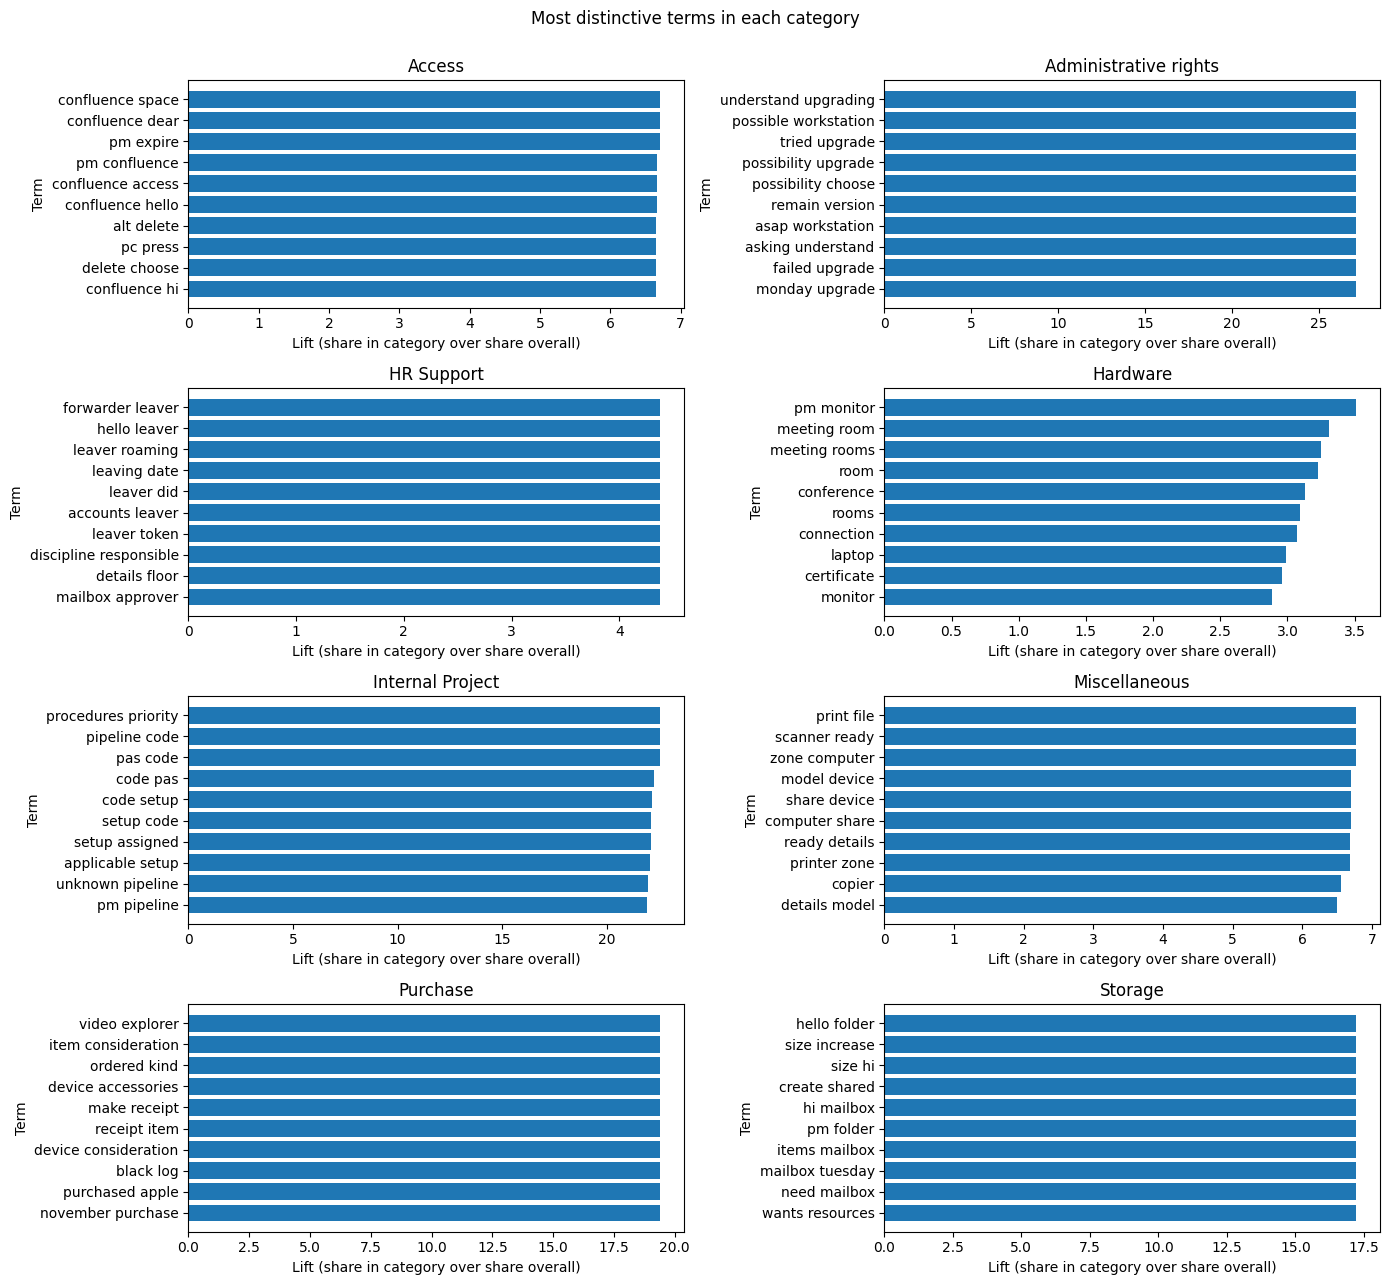

Terms that appear among the top 10 frequent terms of at least half of the categories: 6
['regards', 'thank', 'thanks', 'hi', 'pm', 'hello']


In [66]:
def term_shares(texts, labels, min_df=5):
    vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=min_df, binary=True, max_features=MAX_FEATURES)
    matrix = vectorizer.fit_transform(texts).tocsr()
    terms = np.array(vectorizer.get_feature_names_out())
    overall = np.asarray(matrix.mean(axis=0)).ravel()
    shares = {}
    for name in sorted(labels.unique()):
        mask = (labels == name).to_numpy()
        shares[name] = np.asarray(matrix[mask].mean(axis=0)).ravel()
    return terms, overall, shares

def plot_class_terms(terms, scores_by_class, title, xlabel, filename, n_terms=10):
    names = list(scores_by_class)
    n_cols = 2
    n_rows = int(np.ceil(len(names) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, name in zip(axes, names):
        scores = scores_by_class[name]
        top = np.argsort(scores)[-n_terms:]
        axis.barh(terms[top], scores[top])
        axis.set_title(name)
        axis.set_xlabel(xlabel)
        axis.set_ylabel('Term')
    for axis in axes[len(names):]:
        axis.axis('off')
    fig.suptitle(title, y=1.0)
    save_fig(filename)

terms, overall_share, class_share = term_shares(df['clean_text'], df['label'])

plot_class_terms(terms, class_share, 'Most frequent terms in each category', 'Share of tickets containing the term', 'eda_top_terms_frequent.png')

lift_scores = {}
for name, share in class_share.items():
    lift = np.where(share >= 0.01, share / np.maximum(overall_share, 1e-9), 0.0)
    lift_scores[name] = lift
plot_class_terms(terms, lift_scores, 'Most distinctive terms in each category', 'Lift (share in category over share overall)', 'eda_top_terms_distinctive.png')

top_lists = {name: set(terms[np.argsort(share)[-10:]]) for name, share in class_share.items()}
membership = pd.Series([t for s in top_lists.values() for t in s]).value_counts()
shared_terms = membership[membership >= max(2, n_classes // 2)]
print(f'Terms that appear among the top 10 frequent terms of at least half of the categories: {len(shared_terms)}')
print(list(shared_terms.index))

## Section 6. Split and reference scores

One split is made once, with identical texts kept together. The test set is not used again until the final evaluation. Reference scores show what guessing achieves, so every later score can be read against them. The uniform random guess is the fair bar for macro F1. The most frequent class is the fair bar for accuracy. These reference scores describe the difficulty of the task. No model choice depends on them.

In [67]:
features = df['clean_text']
label_encoder = LabelEncoder().fit(df['label'])
y_all = label_encoder.transform(df['label'])
class_names = list(label_encoder.classes_)

splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(features, y_all, groups=features))
X_train, X_test = features.iloc[train_idx], features.iloc[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
groups_train = X_train
print(f'Train rows: {len(X_train)}, test rows: {len(X_test)}')

split_table = pd.DataFrame({
    'train_percent': (pd.Series(y_train).value_counts(normalize=True).sort_index() * 100).round(2).to_numpy(),
    'test_percent': (pd.Series(y_test).value_counts(normalize=True).sort_index() * 100).round(2).to_numpy(),
}, index=class_names)
display(split_table)

rows = []
for name, strategy in [('Most frequent class', 'most_frequent'), ('Uniform random guess', 'uniform')]:
    dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
    dummy.fit(np.zeros((len(y_train), 1)), y_train)
    guess = dummy.predict(np.zeros((len(y_test), 1)))
    rows.append({'reference': name, 'accuracy': accuracy_score(y_test, guess), 'macro_f1': f1_score(y_test, guess, average='macro', zero_division=0)})
reference_table = pd.DataFrame(rows)
display(reference_table.round(4))
print('Every real model must clearly beat the uniform guess on macro F1 and the most frequent class on accuracy.')

Train rows: 38269, test rows: 9568


,train_percent,test_percent
Access,14.96,14.64
Administrative rights,3.67,3.72
HR Support,22.81,22.86
Hardware,28.46,28.49
Internal Project,4.41,4.52
Miscellaneous,14.87,14.32
Purchase,5.06,5.51
Storage,5.77,5.95


,reference,accuracy,macro_f1
0,Most frequent class,0.2849,0.0554
1,Uniform random guess,0.1297,0.1140


Every real model must clearly beat the uniform guess on macro F1 and the most frequent class on accuracy.


## Section 7. Model comparison for category

Five models are compared. Each sits inside a pipeline that starts with a TF IDF vectorizer, so the vocabulary and the weights are learned only from the training part of each fold. Folds are stratified and grouped by text. XGBoost needs integer labels, which is why labels are encoded once above. Models that support it use balanced class weights. Differences smaller than the spread across folds are ties, and the notebook says so from its own numbers.

Rows used for model comparison and tuning: 20000 of 38269 training rows
Finished Logistic Regression in 49 seconds
Finished LinearSVC in 16 seconds
Finished Multinomial Naive Bayes in 14 seconds
Finished Random Forest in 74 seconds
Finished XGBoost in 79 seconds


,model,macro_f1_mean,macro_f1_std,accuracy_mean,macro_precision_mean,macro_recall_mean,fit_seconds_mean
0,LinearSVC,0.8458,0.0068,0.8426,0.8459,0.8463,1.7337
1,XGBoost,0.8437,0.0089,0.8368,0.8672,0.8244,14.2643
2,Logistic Regression,0.8414,0.0056,0.8379,0.8287,0.8584,8.2713
3,Random Forest,0.8229,0.0090,0.8205,0.8634,0.7934,13.2392
4,Multinomial Naive Bayes,0.6583,0.0103,0.7266,0.8817,0.5967,1.3086


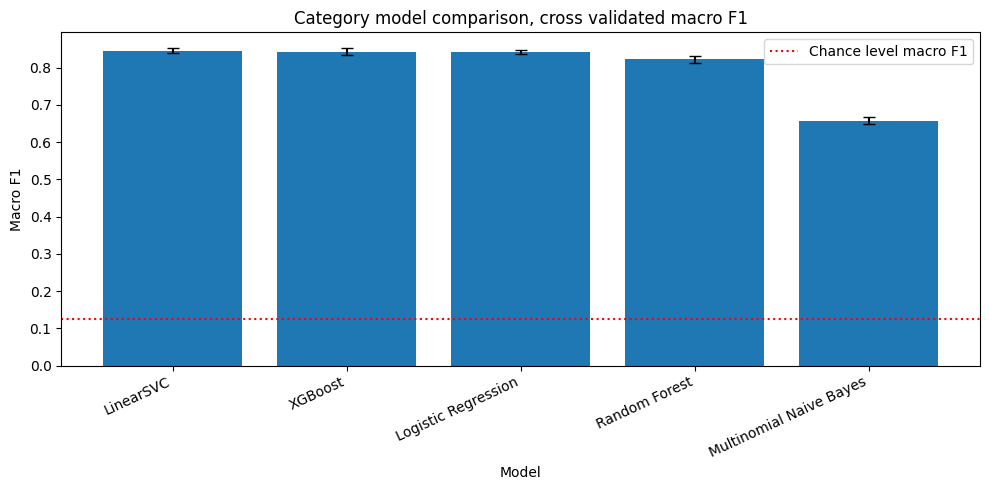

Best model by mean macro F1: LinearSVC (0.8458)
Models within one fold standard deviation of the best, treated as ties: ['LinearSVC', 'XGBoost', 'Logistic Regression']


In [68]:
def make_vectorizer():
    return TfidfVectorizer(stop_words=STOP_WORDS, ngram_range=(1, 2), min_df=3, max_features=MAX_FEATURES, sublinear_tf=True)

def make_models():
    return {
        'Logistic Regression': Pipeline([('tfidf', make_vectorizer()), ('model', LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE))]),
        'LinearSVC': Pipeline([('tfidf', make_vectorizer()), ('model', LinearSVC(class_weight='balanced', max_iter=3000, random_state=RANDOM_STATE))]),
        'Multinomial Naive Bayes': Pipeline([('tfidf', make_vectorizer()), ('model', MultinomialNB())]),
        'Random Forest': Pipeline([('tfidf', make_vectorizer()), ('model', RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=N_JOBS, random_state=RANDOM_STATE))]),
        'XGBoost': Pipeline([('tfidf', make_vectorizer()), ('model', XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5, objective='multi:softprob', eval_metric='mlogloss', tree_method='hist', device=XGB_DEVICE, n_jobs=N_JOBS, random_state=RANDOM_STATE))]),
    }

TUNING_GRIDS = {
    'Logistic Regression': {'model__C': [0.5, 2.0]},
    'LinearSVC': {'model__C': [0.3, 1.0]},
    'Multinomial Naive Bayes': {'model__alpha': [0.1, 0.5]},
    'Random Forest': {'model__max_depth': [None, 40]},
    'XGBoost': {'model__max_depth': [4, 6]},
}

rng = np.random.RandomState(RANDOM_STATE)
if len(X_train) > CV_MAX_ROWS:
    cv_rows = np.sort(rng.choice(len(X_train), CV_MAX_ROWS, replace=False))
else:
    cv_rows = np.arange(len(X_train))
X_cv = X_train.iloc[cv_rows]
y_cv = y_train[cv_rows]
groups_cv = groups_train.iloc[cv_rows]
cv_splitter = StratifiedGroupKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print(f'Rows used for model comparison and tuning: {len(X_cv)} of {len(X_train)} training rows')

def compare_models(X, y, groups, cv):
    scoring = {'macro_f1': 'f1_macro', 'accuracy': 'accuracy', 'macro_precision': 'precision_macro', 'macro_recall': 'recall_macro'}
    rows = []
    for name, model in make_models().items():
        started = time.time()
        values = cross_validate(model, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({
            'model': name,
            'macro_f1_mean': values['test_macro_f1'].mean(),
            'macro_f1_std': values['test_macro_f1'].std(),
            'accuracy_mean': values['test_accuracy'].mean(),
            'macro_precision_mean': values['test_macro_precision'].mean(),
            'macro_recall_mean': values['test_macro_recall'].mean(),
            'fit_seconds_mean': values['fit_time'].mean(),
        })
        print(f'Finished {name} in {time.time() - started:.0f} seconds')
    return pd.DataFrame(rows).sort_values('macro_f1_mean', ascending=False).reset_index(drop=True)

comparison = compare_models(X_cv, y_cv, groups_cv, cv_splitter)
display(comparison.round(4))
comparison.to_csv(OUT_DIR / 'model_comparison_category.csv', index=False)

plt.figure(figsize=(10, 5))
plt.bar(comparison['model'], comparison['macro_f1_mean'], yerr=comparison['macro_f1_std'], capsize=4)
plt.axhline(chance_macro_f1, color='red', linestyle=':', label='Chance level macro F1')
plt.title('Category model comparison, cross validated macro F1')
plt.xlabel('Model')
plt.ylabel('Macro F1')
plt.xticks(rotation=25, ha='right')
plt.legend()
save_fig('model_comparison_category.png')

best_row = comparison.iloc[0]
ties = comparison[comparison['macro_f1_mean'] >= best_row['macro_f1_mean'] - best_row['macro_f1_std']]['model'].tolist()
print(f"Best model by mean macro F1: {best_row['model']} ({best_row['macro_f1_mean']:.4f})")
print(f'Models within one fold standard deviation of the best, treated as ties: {ties}')

### Leakage and signal check

Before trusting the scores, the same Logistic Regression is run with the training labels shuffled at random. A pipeline without leakage must fall to chance level on shuffled labels. A large gap between the real score and the shuffled score is the evidence that the text really carries the category.

In [69]:
shuffled_labels = np.random.RandomState(RANDOM_STATE).permutation(y_cv)
shuffled_scores = cross_validate(make_models()['Logistic Regression'], X_cv, shuffled_labels, groups=groups_cv, cv=cv_splitter, scoring='f1_macro', n_jobs=1)
shuffled_mean = shuffled_scores['test_score'].mean()
real_lr = comparison.loc[comparison['model'] == 'Logistic Regression', 'macro_f1_mean'].iloc[0]
best_f1, best_std = best_row['macro_f1_mean'], best_row['macro_f1_std']

print(f'Chance level macro F1: {chance_macro_f1:.4f}')
print(f'Logistic Regression with shuffled labels: {shuffled_mean:.4f}')
print(f'Logistic Regression with real labels: {real_lr:.4f}')
print(f'Best model with real labels: {best_f1:.4f} (fold standard deviation {best_std:.4f})')
signal_gap = best_f1 - max(chance_macro_f1, shuffled_mean)
if signal_gap > 3 * max(best_std, 0.005):
    print(f'Verdict: the text carries a clear signal for the category. The best model beats chance by {signal_gap:.4f}.')
else:
    print(f'Verdict: no clear signal. The best model beats chance by only {signal_gap:.4f}, which is within normal fold variation.')

Chance level macro F1: 0.1250
Logistic Regression with shuffled labels: 0.1141
Logistic Regression with real labels: 0.8414
Best model with real labels: 0.8458 (fold standard deviation 0.0068)
Verdict: the text carries a clear signal for the category. The best model beats chance by 0.7208.


### Tuning the top two models

A small grid search runs for the two best models, scored on macro F1 with the same grouped folds. The winner is chosen from these cross validation scores only. The test set plays no part.

In [70]:
tuned = []
for name in comparison.head(2)['model']:
    started = time.time()
    search = GridSearchCV(make_models()[name], TUNING_GRIDS[name], scoring='f1_macro', cv=cv_splitter, n_jobs=1, refit=False)
    search.fit(X_cv, y_cv, groups=groups_cv)
    tuned.append({'model': name, 'best_score': search.best_score_, 'best_params': search.best_params_})
    print(f'{name}: best parameters {search.best_params_}, cross validated macro F1 {search.best_score_:.4f} ({time.time() - started:.0f} seconds)')

winner = max(tuned, key=lambda item: item['best_score'])
print(f"Winner chosen by cross validation: {winner['model']} with macro F1 {winner['best_score']:.4f}")

LinearSVC: best parameters {'model__C': 0.3}, cross validated macro F1 0.8493 (24 seconds)
XGBoost: best parameters {'model__max_depth': 6}, cross validated macro F1 0.8437 (119 seconds)
Winner chosen by cross validation: LinearSVC with macro F1 0.8493


## Section 8. Experiment: does removing email boilerplate help?

Tickets contain greetings, sign offs and date or time words such as hi, thanks, regards, weekdays, months and pm. The term analysis showed several of them among the most frequent terms in at least half of the categories. They carry no category meaning, so they could act as noise or as accidental clues. This experiment compares the tuned winner with and without a custom stop word list, on the same folds. The list is adopted only if the gain is larger than the fold spread. Otherwise the original setup stays.

In [71]:
BOILERPLATE_TERMS = [
    'hi', 'hello', 'dear', 'thanks', 'thank', 'regards', 'kind', 'kindly', 'guys', 'team', 'best',
    'pm', 'am', 'sent', 're', 'fw', 'fwd',
    'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday',
    'january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december',
]
CUSTOM_STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) | set(BOILERPLATE_TERMS))

def cv_macro_f1(stop_words_setting):
    global STOP_WORDS
    previous = STOP_WORDS
    STOP_WORDS = stop_words_setting
    try:
        model = clone(make_models()[winner['model']]).set_params(**winner['best_params'])
        values = cross_validate(model, X_cv, y_cv, groups=groups_cv, cv=cv_splitter, scoring='f1_macro', n_jobs=1)
    finally:
        STOP_WORDS = previous
    return values['test_score'].mean(), values['test_score'].std()

base_mean, base_std = cv_macro_f1('english')
custom_mean, custom_std = cv_macro_f1(CUSTOM_STOP_WORDS)
gain = custom_mean - base_mean
print(f"Model used in the experiment: {winner['model']}")
print(f'Standard English stop words: macro F1 {base_mean:.4f} (fold standard deviation {base_std:.4f})')
print(f'With boilerplate terms added: macro F1 {custom_mean:.4f} (fold standard deviation {custom_std:.4f})')
print(f'Gain: {gain:+.4f}')
if gain > max(base_std, custom_std):
    STOP_WORDS = CUSTOM_STOP_WORDS
    STOP_WORDS_CHOICE = 'custom list with email boilerplate removed'
else:
    STOP_WORDS = 'english'
    STOP_WORDS_CHOICE = 'standard English stop words'
print(f'Decision: the final model uses the {STOP_WORDS_CHOICE}.')

Model used in the experiment: LinearSVC
Standard English stop words: macro F1 0.8493 (fold standard deviation 0.0065)
With boilerplate terms added: macro F1 0.8449 (fold standard deviation 0.0059)
Gain: -0.0043
Decision: the final model uses the standard English stop words.


## Section 9. Final evaluation on the test set

The winning model, with the stop word choice from the experiment, is refit once on the full training set and evaluated once on the held out test set. The confusion matrix shows which categories get mixed up, and the weighted terms show how the model decides.

In [72]:
category_model = clone(make_models()[winner['model']]).set_params(**winner['best_params'])
category_model.fit(X_train, y_train)
predicted_test = category_model.predict(X_test)

test_accuracy = accuracy_score(y_test, predicted_test)
test_macro_f1 = f1_score(y_test, predicted_test, average='macro', zero_division=0)
print(f"Final model: {winner['model']}")
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro F1: {test_macro_f1:.4f}')
print(classification_report(y_test, predicted_test, target_names=class_names, zero_division=0))

report = pd.DataFrame(classification_report(y_test, predicted_test, target_names=class_names, zero_division=0, output_dict=True)).T
report.to_csv(OUT_DIR / 'classification_report.csv')
pd.DataFrame([{'model': winner['model'], 'accuracy': test_accuracy, 'macro_f1': test_macro_f1}]).to_csv(OUT_DIR / 'test_metrics.csv', index=False)

Final model: LinearSVC
Test accuracy: 0.8556
Test macro F1: 0.8575
                       precision    recall  f1-score   support

               Access       0.90      0.89      0.89      1401
Administrative rights       0.74      0.81      0.77       356
           HR Support       0.89      0.85      0.87      2187
             Hardware       0.85      0.82      0.83      2726
     Internal Project       0.81      0.91      0.86       432
        Miscellaneous       0.80      0.85      0.82      1370
             Purchase       0.93      0.91      0.92       527
              Storage       0.88      0.90      0.89       569

             accuracy                           0.86      9568
            macro avg       0.85      0.87      0.86      9568
         weighted avg       0.86      0.86      0.86      9568



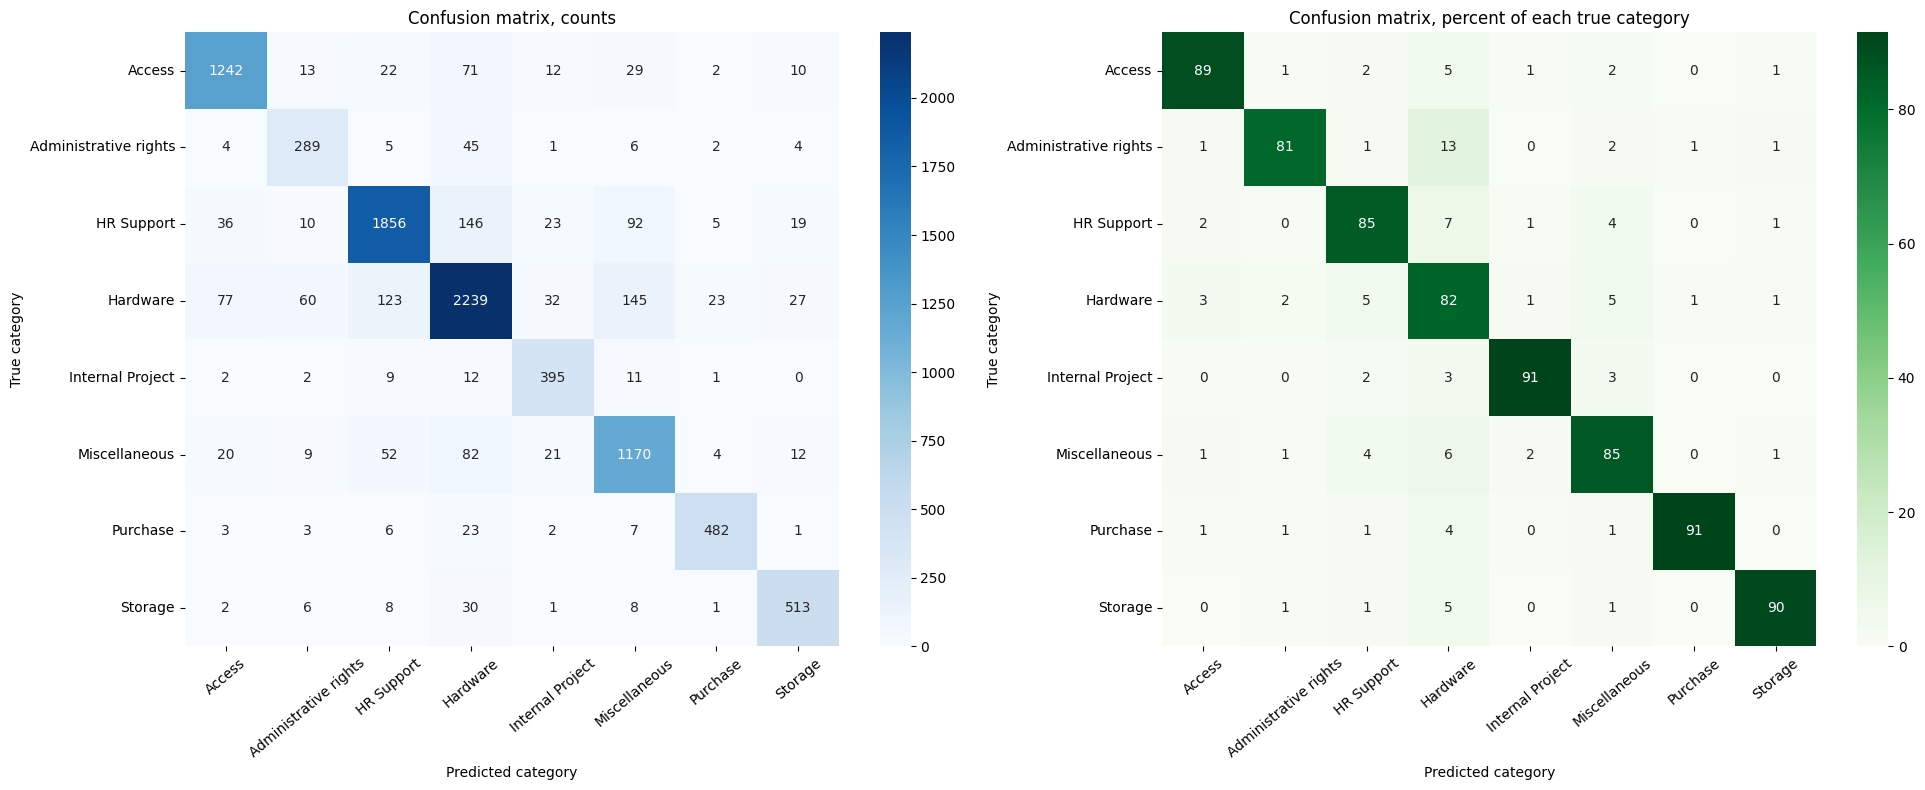

Misclassified tickets: 1382 of 9568
Most confused category pairs


,true_category,predicted_category,count
0,HR Support,Hardware,146
1,Hardware,Miscellaneous,145
2,Hardware,HR Support,123
3,HR Support,Miscellaneous,92
4,Miscellaneous,Hardware,82
5,Hardware,Access,77
6,Access,Hardware,71
7,Hardware,Administrative rights,60
8,Miscellaneous,HR Support,52
9,Administrative rights,Hardware,45


Ten misclassified tickets


,true_category,predicted_category,text
2353,Hardware,HR Support,access for thursday july pm hi guys please kindly help granting she order upload contracts performed thank...
5495,Hardware,Administrative rights,headphones tuesday october pm headphones dear headphones attend daily meetings client started working head...
1872,Miscellaneous,HR Support,doubled addresses doubled addresses hello several colleagues same although different persons employees sam...
6016,HR Support,Storage,access to location location hi please provide layouts source ancient polls thank analyst ext
5750,Hardware,Access,new quarantine account information required wednesday october dear received find suspicious please legitim...
4873,Miscellaneous,HR Support,amending tuesday december pm amending hello please thank
462,Access,Purchase,admin rights on rights dear please create provide rights provide cr which include patch installation updat...
1274,Hardware,Miscellaneous,please install us application updated please install application installation needed more director october...
5523,Access,Miscellaneous,improvements project october improvements hi guys type issue added improvement please add type thank octob...
3671,Access,Miscellaneous,snow instance access march pm snow instance hello instance training purposes starter please help out her g...


In [73]:
counts = confusion_matrix(y_test, predicted_test, labels=range(len(class_names)))
percentages = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(counts, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion matrix, counts')
sns.heatmap(percentages, annot=True, fmt='.0f', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion matrix, percent of each true category')
for axis in axes:
    axis.set_xlabel('Predicted category')
    axis.set_ylabel('True category')
    axis.tick_params(axis='x', rotation=40)
save_fig('confusion_category.png')

errors = pd.DataFrame({
    'true_category': label_encoder.inverse_transform(y_test),
    'predicted_category': label_encoder.inverse_transform(predicted_test.astype(int)),
    'text': X_test.str.slice(0, 140).to_numpy(),
})
wrong = errors[errors['true_category'] != errors['predicted_category']]
print(f'Misclassified tickets: {len(wrong)} of {len(errors)}')
pairs = wrong.groupby(['true_category', 'predicted_category']).size().sort_values(ascending=False).reset_index(name='count')
print('Most confused category pairs')
display(pairs.head(10))
print('Ten misclassified tickets')
display(wrong.sample(min(10, len(wrong)), random_state=RANDOM_STATE))

Weighted terms come from: LinearSVC


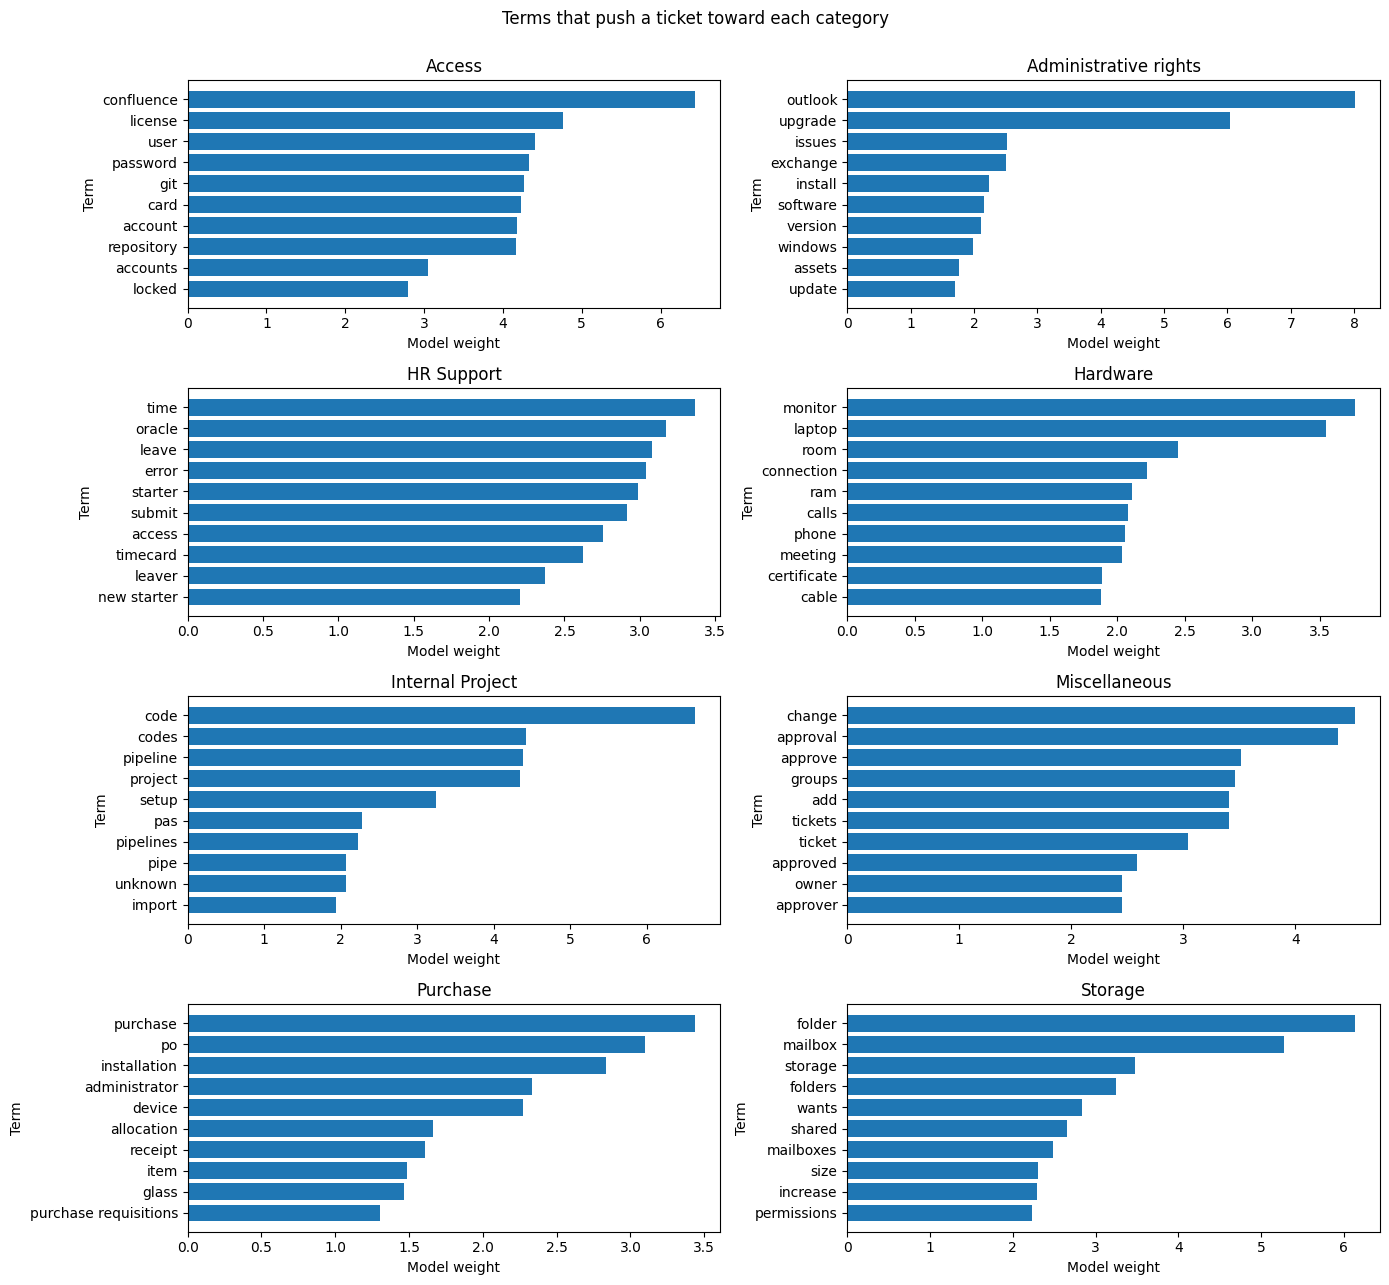

In [74]:
fitted_estimator = category_model.named_steps['model']
if hasattr(fitted_estimator, 'coef_'):
    explainer = category_model
    explainer_name = winner['model']
else:
    explainer = Pipeline([('tfidf', make_vectorizer()), ('model', LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE))]).fit(X_train, y_train)
    explainer_name = 'Logistic Regression (explanation model, the winner has no readable weights)'
print(f'Weighted terms come from: {explainer_name}')

weights = explainer.named_steps['model'].coef_
weight_terms = explainer.named_steps['tfidf'].get_feature_names_out()
plot_class_terms(weight_terms, {class_names[i]: weights[i] for i in range(len(class_names))}, 'Terms that push a ticket toward each category', 'Model weight', 'top_terms_model_category.png')

## Section 10. Calibrated confidence by temperature scaling

A model score is not yet a probability. The raw softmax of LinearSVC decision values is compressed, so a correct prediction can show a confidence near 0.25. Version 2 wrapped the model in sigmoid calibration, which made the confidence underconfident and also changed 5.9 percent of the predictions.

Temperature scaling avoids both problems. The winning model stays exactly as it is, so its predictions do not change. One number, the temperature, is fitted on out of fold scores from the training set, and the probabilities are the softmax of the scores divided by that temperature. The test set is used once to check the result. The reliability table shows whether a confidence of 0.8 really means about 80 percent correct. The coverage table shows what a support team could route automatically above a confidence threshold, with the rest going to a person.

In [75]:
def softmax(scores):
    shifted = scores - scores.max(axis=1, keepdims=True)
    exps = np.exp(shifted)
    return exps / exps.sum(axis=1, keepdims=True)

def get_scores(model, texts):
    if hasattr(model, 'decision_function'):
        return np.asarray(model.decision_function(texts))
    return np.log(np.clip(model.predict_proba(texts), 1e-9, 1.0))

def log_loss_value(probabilities, y_true):
    chosen = probabilities[np.arange(len(y_true)), y_true]
    return float(-np.mean(np.log(np.clip(chosen, 1e-12, 1.0))))

def expected_calibration_error(confidence_values, correct_values, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence_values > low) & (confidence_values <= high)
        if in_bin.any():
            total += in_bin.mean() * abs(correct_values[in_bin].mean() - confidence_values[in_bin].mean())
    return float(total)

score_method = 'decision_function' if hasattr(category_model, 'decision_function') else 'predict_proba'
oof_cv = StratifiedGroupKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
oof_scores = cross_val_predict(clone(category_model), X_train, y_train, groups=groups_train, cv=oof_cv, method=score_method, n_jobs=1)
if score_method == 'predict_proba':
    oof_scores = np.log(np.clip(oof_scores, 1e-9, 1.0))

temperature_grid = np.exp(np.linspace(np.log(0.02), np.log(5.0), 150))
oof_losses = [log_loss_value(softmax(oof_scores / t), y_train) for t in temperature_grid]
TEMPERATURE = float(temperature_grid[int(np.argmin(oof_losses))])
print(f'Scores come from: {score_method}')
print(f'Fitted temperature: {TEMPERATURE:.4f}')
print(f'Out of fold log loss at temperature 1: {log_loss_value(softmax(oof_scores), y_train):.4f}')
print(f'Out of fold log loss at the fitted temperature: {min(oof_losses):.4f}')
if TEMPERATURE in (float(temperature_grid[0]), float(temperature_grid[-1])):
    print('Warning: the fitted temperature sits at the edge of the search range. Check the scores before trusting the calibration.')

Scores come from: decision_function
Fitted temperature: 0.2778
Out of fold log loss at temperature 1: 0.9243
Out of fold log loss at the fitted temperature: 0.4291


In [76]:
test_scores = get_scores(category_model, X_test)
raw_probabilities = softmax(test_scores)
scaled_probabilities = softmax(test_scores / TEMPERATURE)
deployed_pred = predicted_test
deployed_accuracy = test_accuracy
deployed_macro_f1 = test_macro_f1
confidence = scaled_probabilities.max(axis=1)
raw_confidence = raw_probabilities.max(axis=1)
correct = deployed_pred == y_test

print(f'Share of test tickets where the scaled probabilities pick the same category as the model: {(scaled_probabilities.argmax(axis=1) == deployed_pred).mean():.3f}')

metrics_table = pd.DataFrame({
    'version': ['Raw softmax of scores', 'Temperature scaled'],
    'test_accuracy': [test_accuracy, test_accuracy],
    'test_macro_f1': [test_macro_f1, test_macro_f1],
    'test_log_loss': [log_loss_value(raw_probabilities, y_test), log_loss_value(scaled_probabilities, y_test)],
    'expected_calibration_error': [expected_calibration_error(raw_confidence, correct), expected_calibration_error(confidence, correct)],
    'mean_confidence': [raw_confidence.mean(), confidence.mean()],
})
display(metrics_table.round(4))
metrics_table.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
print(f'Share of test tickets predicted correctly: {correct.mean():.4f}')

Share of test tickets where the scaled probabilities pick the same category as the model: 1.000


,version,test_accuracy,test_macro_f1,test_log_loss,expected_calibration_error,mean_confidence
0,Raw softmax of scores,0.8556,0.8575,0.8951,0.3716,0.4839
1,Temperature scaled,0.8556,0.8575,0.4331,0.0256,0.8680


Share of test tickets predicted correctly: 0.8556


,bucket,tickets,mean_confidence,accuracy
0,"(-0.001, 0.4]",304,0.341,0.411
1,"(0.4, 0.5]",441,0.452,0.497
2,"(0.5, 0.6]",553,0.547,0.575
3,"(0.6, 0.7]",538,0.652,0.664
4,"(0.7, 0.8]",646,0.751,0.734
5,"(0.8, 0.9]",852,0.854,0.817
6,"(0.9, 1.0]",6234,0.984,0.962


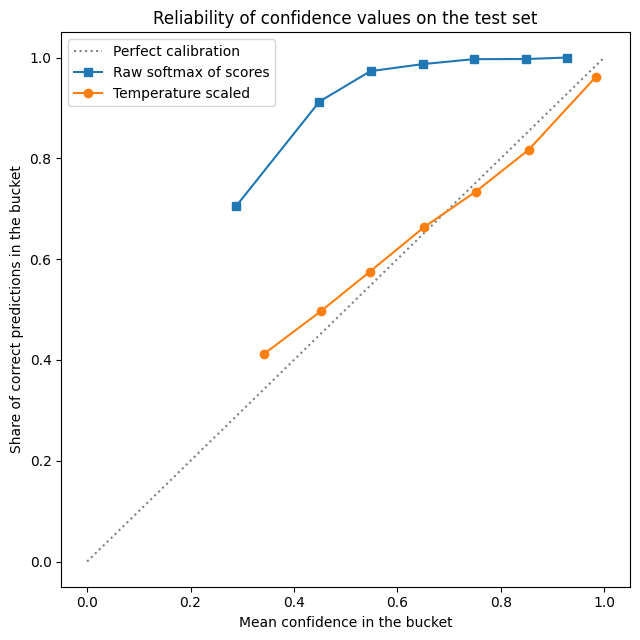

,confidence_at_least,share_of_tickets,accuracy_on_those
0,0.5,0.922,0.889
1,0.6,0.864,0.910
2,0.7,0.808,0.927
3,0.8,0.741,0.945
4,0.9,0.652,0.962


Reading the table: tickets above a threshold could be routed automatically, and the rest go to a person.


In [77]:
bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def reliability_table(confidence_values, correct_values):
    bucket = pd.cut(confidence_values, bins=bins, include_lowest=True)
    table = (pd.DataFrame({'bucket': bucket, 'confidence': confidence_values, 'correct': correct_values})
             .groupby('bucket', observed=True)
             .agg(tickets=('correct', 'size'), mean_confidence=('confidence', 'mean'), accuracy=('correct', 'mean'))
             .reset_index())
    table['bucket'] = table['bucket'].astype(str)
    return table

reliability = reliability_table(confidence, correct)
raw_reliability = reliability_table(raw_confidence, correct)
display(reliability.round(3))
reliability.to_csv(OUT_DIR / 'confidence_reliability.csv', index=False)

plt.figure(figsize=(6.5, 6.5))
plt.plot([0, 1], [0, 1], linestyle=':', color='grey', label='Perfect calibration')
plt.plot(raw_reliability['mean_confidence'], raw_reliability['accuracy'], marker='s', label='Raw softmax of scores')
plt.plot(reliability['mean_confidence'], reliability['accuracy'], marker='o', label='Temperature scaled')
plt.title('Reliability of confidence values on the test set')
plt.xlabel('Mean confidence in the bucket')
plt.ylabel('Share of correct predictions in the bucket')
plt.legend()
save_fig('calibration_category.png')

coverage_rows = []
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = confidence >= threshold
    coverage_rows.append({
        'confidence_at_least': threshold,
        'share_of_tickets': keep.mean(),
        'accuracy_on_those': correct[keep].mean() if keep.any() else np.nan,
    })
coverage = pd.DataFrame(coverage_rows)
display(coverage.round(3))
coverage.to_csv(OUT_DIR / 'confidence_coverage.csv', index=False)
print('Reading the table: tickets above a threshold could be routed automatically, and the rest go to a person.')

## Section 11. Priority rules

Priority is decided by points. Each urgency rule that matches the ticket text adds or removes points, once per rule, and a small weight is added for the predicted category. The total is turned into High, Medium or Low with two thresholds. The rules, the weights and the thresholds are design choices, written out below so a support manager can read and change them. They are not learned from labelled data, so no accuracy is claimed for them until a person has reviewed a sample.

Changes after the version 2 rule audit: the routine request rule keeps only specific phrases, because polite phrases such as please advise, information and request for also appear in tickets from blocked users. The word server was removed from wide impact. Broken devices and features, which are usually one person's problem, now score 2 points, while outages and failures keep 3. Scheduled or planned wording now removes 3 points. The rules are applied to the predicted category, because the true category is not known when a ticket arrives.

In [78]:
RULES_VERSION = 3
URGENCY_RULES = [
    ('explicit urgency', 3, r'\b(urgent\w*|asap|immediate\w*|emergency|critical|deadline)\b'),
    ('service failure', 3, r'\b(outage|down|crash\w*|fail\w*|freez\w*|frozen|corrupt\w*|dead)\b'),
    ('device or feature not working', 2, r'\b(broken|not working|stopped working|no longer working)\b'),
    ('security or data risk', 3, r'\b(security|breach\w*|virus|malware|phishing|hack\w*|ransomware|leak\w*|stolen|suspicious|data loss)\b'),
    ('blocked from working', 2, r'\b(unable|cannot|blocked|locked|lockout|denied|deny|unavailable|stuck|cant)\b|\bcan t\b'),
    ('wide impact', 2, r'\b(everyone|everybody|all users|all staff|whole team|entire team|entire office|multiple users|company wide|team wide)\b'),
    ('sender marked high importance', 1, r'\bimportance high\b'),
    ('degraded service', 1, r'\b(slow\w*|lag\w*|intermittent\w*|delay\w*|sometimes|error\w*)\b'),
    ('routine request', -2, r'\b(how to|how do|question|inquiry|new starter|upgrade|quote|would like|wondering|recommend\w*)\b'),
    ('scheduled or planned', -3, r'\b(scheduled|planned)\b'),
    ('maintenance notice', -4, r'\bmaintenance\b'),
]
COMPILED_RULES = [(name, points, re.compile(pattern)) for name, points, pattern in URGENCY_RULES]

CATEGORY_WEIGHT_HINTS = {'access': 1, 'administrative': 1, 'hardware': 1, 'storage': 1, 'purchase': -1, 'miscellaneous': -1}
HIGH_AT = 4
MEDIUM_AT = 2

def category_weight(category_name):
    name = str(category_name).lower()
    for hint, weight in CATEGORY_WEIGHT_HINTS.items():
        if hint in name:
            return weight
    return 0

def level_from_points(points, high_at=HIGH_AT, medium_at=MEDIUM_AT):
    if points >= high_at:
        return 'High'
    if points >= medium_at:
        return 'Medium'
    return 'Low'

def assign_priority(clean, category_name):
    matched_rules = []
    matched_terms = []
    points = 0
    for name, rule_points, pattern in COMPILED_RULES:
        found = pattern.search(clean)
        if found:
            matched_rules.append(name)
            matched_terms.append(found.group(0))
            points += rule_points
    points += category_weight(category_name)
    return level_from_points(points), points, matched_rules, matched_terms

print(f'Rules version: {RULES_VERSION}')
display(pd.DataFrame(URGENCY_RULES, columns=['rule', 'points', 'pattern']))
print('Category weights applied to the categories in this dataset')
display(pd.DataFrame({'category': class_names, 'weight': [category_weight(c) for c in class_names]}))
print(f'Thresholds: High at {HIGH_AT} points or more, Medium at {MEDIUM_AT} points or more, otherwise Low')

Rules version: 3


,rule,points,pattern
0,explicit urgency,3,\b(urgent\w*|asap|immediate\w*|emergency|critical|deadline)\b
1,service failure,3,\b(outage|down|crash\w*|fail\w*|freez\w*|frozen|corrupt\w*|dead)\b
2,device or feature not working,2,\b(broken|not working|stopped working|no longer working)\b
3,security or data risk,3,\b(security|breach\w*|virus|malware|phishing|hack\w*|ransomware|leak\w*|stolen|suspicious|data loss)\b
4,blocked from working,2,\b(unable|cannot|blocked|locked|lockout|denied|deny|unavailable|stuck|cant)\b|\bcan t\b
5,wide impact,2,\b(everyone|everybody|all users|all staff|whole team|entire team|entire office|multiple users|company wide...
6,sender marked high importance,1,\bimportance high\b
7,degraded service,1,\b(slow\w*|lag\w*|intermittent\w*|delay\w*|sometimes|error\w*)\b
8,routine request,-2,\b(how to|how do|question|inquiry|new starter|upgrade|quote|would like|wondering|recommend\w*)\b
9,scheduled or planned,-3,\b(scheduled|planned)\b


Category weights applied to the categories in this dataset


,category,weight
0,Access,1
1,Administrative rights,1
2,HR Support,0
3,Hardware,1
4,Internal Project,0
5,Miscellaneous,-1
6,Purchase,-1
7,Storage,1


Thresholds: High at 4 points or more, Medium at 2 points or more, otherwise Low


,tickets,percent
priority,,
High,969,10.1
Medium,1337,14.0
Low,7262,75.9


Tickets that matched no urgency rule: 61.5 percent


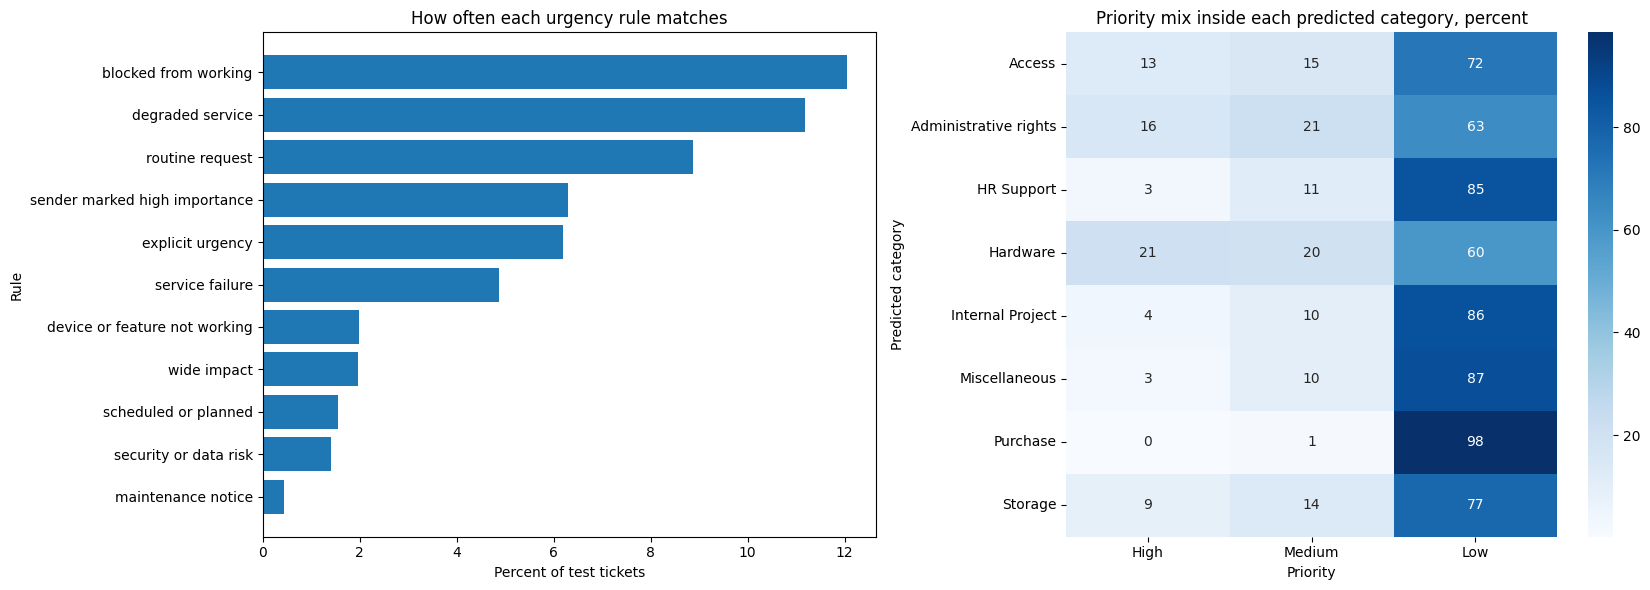

Share of tickets that change level if both thresholds move up by one point: 10.8 percent
Share of tickets that change level if both thresholds move down by one point: 44.7 percent


In [79]:
predicted_names = label_encoder.inverse_transform(deployed_pred.astype(int))
true_names = label_encoder.inverse_transform(y_test)
assigned = [assign_priority(text, category) for text, category in zip(X_test.to_numpy(), predicted_names)]
priority_frame = pd.DataFrame({
    'ticket_id': np.arange(len(X_test)),
    'clean_text': X_test.to_numpy(),
    'true_category': true_names,
    'predicted_category': predicted_names,
    'priority': [a[0] for a in assigned],
    'points': [a[1] for a in assigned],
    'rules': [', '.join(a[2]) for a in assigned],
    'terms': [', '.join(a[3]) for a in assigned],
})

level_order = ['High', 'Medium', 'Low']
level_counts = priority_frame['priority'].value_counts().reindex(level_order).fillna(0).astype(int)
display(pd.DataFrame({'tickets': level_counts, 'percent': (level_counts / level_counts.sum() * 100).round(1)}))

no_rule_share = (priority_frame['rules'] == '').mean() * 100
print(f'Tickets that matched no urgency rule: {no_rule_share:.1f} percent')

rule_hits = pd.Series({name: priority_frame['rules'].str.contains(name, regex=False).mean() * 100 for name, _, _ in URGENCY_RULES}).sort_values()
for name, share in rule_hits.items():
    if share > 25:
        print(f'Check the rule {name}: it matches {share:.1f} percent of tickets, which is a lot.')

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].barh(rule_hits.index, rule_hits.values)
axes[0].set_title('How often each urgency rule matches')
axes[0].set_xlabel('Percent of test tickets')
axes[0].set_ylabel('Rule')
mix = pd.crosstab(priority_frame['predicted_category'], priority_frame['priority'], normalize='index').reindex(columns=level_order).fillna(0) * 100
sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', ax=axes[1])
axes[1].set_title('Priority mix inside each predicted category, percent')
axes[1].set_xlabel('Priority')
axes[1].set_ylabel('Predicted category')
save_fig('priority_rules_overview.png')

def share_changed(shift):
    shifted = priority_frame['points'].map(lambda p: level_from_points(p, HIGH_AT + shift, MEDIUM_AT + shift))
    return (shifted != priority_frame['priority']).mean() * 100

print(f'Share of tickets that change level if both thresholds move up by one point: {share_changed(1):.1f} percent')
print(f'Share of tickets that change level if both thresholds move down by one point: {share_changed(-1):.1f} percent')

### How category mistakes move priority

Priority uses the predicted category, so a wrong category can change the points. This cell measures how often that happens.

In [80]:
levels_with_true_category = np.array([assign_priority(t, c)[0] for t, c in zip(priority_frame['clean_text'], priority_frame['true_category'])])
level_changed = levels_with_true_category != priority_frame['priority'].to_numpy()
wrong_category = deployed_pred != y_test
print(f'Share of all tickets whose priority level would change if the true category were known: {level_changed.mean() * 100:.1f} percent')
if wrong_category.any():
    print(f'Among tickets with a wrong predicted category, the share whose level changes: {level_changed[wrong_category].mean() * 100:.1f} percent')
else:
    print('No wrong category predictions in the test set, so there is nothing to measure here.')

Share of all tickets whose priority level would change if the true category were known: 1.9 percent
Among tickets with a wrong predicted category, the share whose level changes: 13.3 percent


### Rule audit

For each rule, the words that trigger it most often and a few matches shown in context. This is where false triggers show up.

In [81]:
test_texts = priority_frame['clean_text'].tolist()
audit_rng = np.random.RandomState(RANDOM_STATE)
term_rows = []
context_rows = []
for name, points, pattern in COMPILED_RULES:
    matches = [(text, found) for text in test_texts for found in [pattern.search(text)] if found]
    counts = pd.Series([found.group(0) for _, found in matches], dtype=object).value_counts().head(5)
    term_rows.append({'rule': name, 'tickets_matched': len(matches), 'top_triggering_terms': ', '.join(f'{term} ({n})' for term, n in counts.items())})
    if matches:
        for j in audit_rng.choice(len(matches), min(3, len(matches)), replace=False):
            text, found = matches[j]
            context_rows.append({'rule': name, 'term': found.group(0), 'context': text[max(0, found.start() - 45): found.end() + 45]})
display(pd.DataFrame(term_rows))
display(pd.DataFrame(context_rows))

,rule,tickets_matched,top_triggering_terms
0,explicit urgency,593,"urgent (195), asap (135), immediately (81), critical (77), deadline (38)"
1,service failure,467,"down (173), failed (135), failure (25), failing (25), fail (22)"
2,device or feature not working,191,"not working (127), broken (50), stopped working (13), no longer working (1)"
3,security or data risk,135,"security (42), virus (40), suspicious (20), breached (14), breaching (6)"
4,blocked from working,1153,"cannot (632), unable (322), locked (60), unavailable (41), blocked (38)"
5,wide impact,189,"everyone (143), all staff (26), everybody (8), all users (6), multiple users (5)"
6,sender marked high importance,602,importance high (602)
7,degraded service,1070,"error (854), errors (73), slow (51), sometimes (34), delay (28)"
8,routine request,849,"new starter (389), upgrade (180), question (101), would like (51), recommended (41)"
9,scheduled or planned,148,"planned (83), scheduled (65)"


,rule,term,context
0,explicit urgency,asap,ed also collaboration thus importance having asap high thanks head
1,explicit urgency,urgent,sue computation please assign since he enter urgent query once issue resolved close thank kind r
2,explicit urgency,urgent,help changing client site think change kind urgent due tomorrow expire thanks pm expire days im
3,service failure,failed,issues certificate verify failed issues certificate verify failed hello can y
4,service failure,failed,upgrade la upgrade mea task sequence upgrade failed with error code for more information contact
5,service failure,failing,file upload to failing please help file upload failing please help
6,device or feature not working,not working,still not working after incident sent thursday re notification
7,device or feature not working,not working,leaver form not working properly and missing belgrade location sent
8,device or feature not working,not working,not working sent friday speaker issue olympus hi tried a
9,security or data risk,suspicious,add address to filter re suspicious thank vigilance has dangerous content guess


In [82]:
print('Examples for reading and sanity checking')
for level in level_order:
    subset = priority_frame[priority_frame['priority'] == level]
    print(f'{level} priority examples ({len(subset)} tickets in total)')
    if len(subset):
        display(subset.sample(min(4, len(subset)), random_state=RANDOM_STATE)[['clean_text', 'predicted_category', 'points', 'rules', 'terms']].assign(clean_text=lambda x: x['clean_text'].str.slice(0, 120)))

Examples for reading and sanity checking
High priority examples (969 tickets in total)


,clean_text,predicted_category,points,rules,terms
7673,investigate further breach for per she does remember re opening,Administrative rights,4,security or data risk,breach
4528,your password expire days support to change password re expire days change hi please help changing client ...,Access,5,"explicit urgency, sender marked high importance","urgent, importance high"
6163,laptop failure friday pm failure hello today had issue boot approached gave him repair taken after lunch w...,Hardware,4,service failure,failure
7183,time card error card error hi while trying enter annual leave record stuck with error condition card canno...,HR Support,6,"service failure, blocked from working, degraded service","down, stuck, error"


Medium priority examples (1337 tickets in total)


,clean_text,predicted_category,points,rules,terms
7895,outlook configuration default address left panel cannot access calendar or any other navigation option any...,Administrative rights,3,blocked from working,cannot
8512,unable to access sent thursday access hi can you please help with access when trying below message display...,Hardware,3,blocked from working,unable
9268,wireless connections are not working hello laptop having issues with wireless connections there networks f...,Hardware,3,device or feature not working,not working
3590,sonar access for thursday march re hello updated file name his ad thanks wednesday march pm hello please a...,Access,3,blocked from working,cannot


Low priority examples (7262 tickets in total)


,clean_text,predicted_category,points,rules,terms
1646,ports to be live the its area ports area hello area number desks which phone ports available discussed tec...,Hardware,1,,
3401,en replacement tuesday pm hello please person possesses has requested replacement which has approved has w...,Hardware,-1,routine request,upgrade
3346,po tuesday hi please log installation install recently purchased notebook ca cell machine thanks administr...,Purchase,-1,,
5621,new starter extra ad bucharest october starter ad good morning thank contacting unfortunately hardware par...,HR Support,-2,routine request,new starter


### Human review of the rules

The review sample has 60 test tickets: 30 that contain at least one urgency word from a fixed sampling list, and 30 that contain none. The second group shows whether the rules miss urgent tickets that use other wording. The sampling list is separate from the scoring rules and never changes, and the sample uses only the ticket text, so it stays the same when the rules or the model change. Your labels therefore remain valid after every rule change.

How to review, in short. Open `priority_review_sample.csv`, read only the ticket text, and fill the `reviewer_priority` column with High, Medium or Low. Use the optional `reviewer_note` column when a ticket is unclear. The full guide is saved as `priority_review_guide.txt` and is printed below.

On Kaggle, download the review file from the Output tab, fill it in on your computer, upload it as a Kaggle dataset, and add that dataset as an input to the notebook. The agreement cell looks for the file there. Locally, put the filled file in the `outputs/it_tickets` folder.

In [83]:
REVIEW_GUIDE = '''How to review the tickets

Read only the ticket text. Do not think about the category.

High: work is stopped or at serious risk right now, many people are affected, there is a security or data risk, or the sender gives a real urgent deadline. A response is needed within hours.
Medium: one person or a small group is blocked, or something important is failing, but work can continue in some way and nothing is on fire. A response is needed the same or the next working day.
Low: a request, a question, an access setup, a new starter or a routine change. Nothing is broken or blocked. The normal queue is fine.

When you are unsure, pick the level you would defend to a support manager, and add a short note.
'''
REVIEW_LEXICON = re.compile(r'\b(urgent\w*|asap|immediate\w*|emergency|critical|deadline|outage|down|crash\w*|fail\w*|broken|not working|unable|cannot|blocked|locked|unavailable|security|virus|breach\w*|everyone|all staff|slow\w*|error\w*|importance high|scheduled|planned|maintenance)\b')

review_path = OUT_DIR / 'priority_review_sample.csv'
guide_path = OUT_DIR / 'priority_review_guide.txt'
guide_path.write_text(REVIEW_GUIDE)
print(REVIEW_GUIDE)

if not review_path.exists():
    has_word = priority_frame['clean_text'].map(lambda t: bool(REVIEW_LEXICON.search(t)))
    with_word = priority_frame[has_word]
    without_word = priority_frame[~has_word]
    review_sample = pd.concat([
        with_word.sample(min(30, len(with_word)), random_state=RANDOM_STATE),
        without_word.sample(min(30, len(without_word)), random_state=RANDOM_STATE),
    ]).sample(frac=1, random_state=RANDOM_STATE)
    review_sample[['ticket_id', 'clean_text']].assign(reviewer_priority='', reviewer_note='').to_csv(review_path, index=False)
    print(f'Review file written: {review_path}')
else:
    print(f'Review file already exists and is kept as is: {review_path}')

How to review the tickets

Read only the ticket text. Do not think about the category.

High: work is stopped or at serious risk right now, many people are affected, there is a security or data risk, or the sender gives a real urgent deadline. A response is needed within hours.
Medium: one person or a small group is blocked, or something important is failing, but work can continue in some way and nothing is on fire. A response is needed the same or the next working day.
Low: a request, a question, an access setup, a new starter or a routine change. Nothing is broken or blocked. The normal queue is fine.

When you are unsure, pick the level you would defend to a support manager, and add a short note.

Review file already exists and is kept as is: /kaggle/working/outputs/it_tickets/priority_review_sample.csv


In [84]:
def load_filled_review():
    candidates = [review_path]
    if Path('/kaggle/input').exists():
        candidates += sorted(Path('/kaggle/input').rglob('priority_review_sample*.csv'))
    best = None
    for candidate in candidates:
        try:
            table = pd.read_csv(candidate, dtype=str, keep_default_na=False)
            table['ticket_id'] = table['ticket_id'].astype(int)
            table['reviewer_priority'] = table['reviewer_priority'].str.strip().str.title()
        except Exception:
            continue
        count = int(table['reviewer_priority'].isin(['High', 'Medium', 'Low']).sum())
        if best is None or count > best[2]:
            best = (candidate, table, count)
    return best

REVIEW_DONE = False
REVIEW_RESULTS = {}
loaded = load_filled_review()
if loaded is None or loaded[2] < 30:
    print('Fewer than 30 tickets have a reviewer_priority yet. Fill the review file, then rerun this cell.')
else:
    review_source, reviewed, filled_count = loaded
    REVIEW_DONE = True
    filled = reviewed[reviewed['reviewer_priority'].isin(level_order)].copy()
    if 'reviewer_note' not in filled.columns:
        filled['reviewer_note'] = ''
    current = priority_frame[['ticket_id', 'clean_text', 'priority', 'points', 'rules', 'terms']].rename(columns={'priority': 'rule_priority', 'clean_text': 'clean_text_now'})
    merged = filled.merge(current, on='ticket_id')
    if not (merged['clean_text'] == merged['clean_text_now']).all():
        print('Warning: some review tickets no longer match the current test split. The data or the seed changed.')
    rank = {'Low': 0, 'Medium': 1, 'High': 2}
    gap = (merged['reviewer_priority'].map(rank) - merged['rule_priority'].map(rank)).abs()
    merged['has_urgency_word'] = merged['clean_text'].map(lambda t: bool(REVIEW_LEXICON.search(t)))
    merged['agree'] = gap == 0

    print(f'Review file used: {review_source}')
    print(f'Reviewed tickets: {len(merged)}')
    print('How the reviewer labelled them')
    display(merged['reviewer_priority'].value_counts().reindex(level_order).fillna(0).astype(int))
    print(f'Exact agreement: {(gap == 0).mean():.2f}')
    print(f'Within one level: {(gap <= 1).mean():.2f}')
    print(f'Serious misses, High against Low: {int((gap == 2).sum())}')
    REVIEW_RESULTS = {'reviewed': int(len(merged)), 'exact_agreement': float((gap == 0).mean()), 'within_one_level': float((gap <= 1).mean()), 'serious_misses': int((gap == 2).sum())}

    print('Reviewer label (rows) against rule priority (columns)')
    display(pd.crosstab(merged['reviewer_priority'], merged['rule_priority']).reindex(index=level_order, columns=level_order).fillna(0).astype(int))
    print('Agreement within each rule level')
    display(merged.groupby('rule_priority')['agree'].agg(['mean', 'size']).reindex(level_order).round(2))
    print('Agreement by sample group')
    display(merged.groupby('has_urgency_word')['agree'].agg(['mean', 'size']).rename(index={True: 'contains an urgency word', False: 'contains no urgency word'}).round(2))

    disagreements = merged[~merged['agree']].assign(gap=gap[~merged['agree']]).sort_values('gap', ascending=False)
    print('Disagreements, biggest gaps first')
    display(disagreements[['reviewer_priority', 'rule_priority', 'points', 'rules', 'terms', 'reviewer_note']].assign(text=disagreements['clean_text'].str.slice(0, 130)).head(20))

    grid_rows = []
    for high_at in [3, 4, 5, 6]:
        for medium_at in [1, 2, 3]:
            if medium_at < high_at:
                shifted = merged['points'].map(lambda p: level_from_points(p, high_at, medium_at))
                shifted_gap = (merged['reviewer_priority'].map(rank) - shifted.map(rank)).abs()
                grid_rows.append({'high_at': high_at, 'medium_at': medium_at, 'exact_agreement': (shifted_gap == 0).mean(), 'serious_misses': int((shifted_gap == 2).sum())})
    print('Threshold check on the reviewed tickets (indicative only, the sample is small)')
    display(pd.DataFrame(grid_rows).sort_values(['exact_agreement', 'serious_misses'], ascending=[False, True]).round(3))

Review file used: /kaggle/input/datasets/cyrusndungungugi/priority-review-sample-csv/priority_review_sample.csv
Reviewed tickets: 60
How the reviewer labelled them


reviewer_priority
High       8
Medium    22
Low       30
Name: count, dtype: int64

Exact agreement: 0.58
Within one level: 0.88
Serious misses, High against Low: 7
Reviewer label (rows) against rule priority (columns)


rule_priority,High,Medium,Low
reviewer_priority,,,
High,2,3,3
Medium,5,10,7
Low,4,3,23


Agreement within each rule level


,mean,size
rule_priority,,
High,0.18,11
Medium,0.62,16
Low,0.70,33


... (2 outputs left out)

Disagreements, biggest gaps first


,reviewer_priority,rule_priority,points,rules,terms,reviewer_note,text
1,Low,High,8,"service failure, security or data risk, degraded service","crashing, security, slow",,degraded performance of laptop after installing security updates degraded performance after installing upd...
39,Low,High,8,"explicit urgency, service failure, blocked from working, degraded service, routine request","deadline, down, unable, slow, recommend",,migration from old to new hello please advise where he migrate his content create site where must create t...
31,Low,High,4,security or data risk,security,,security updates sent tuesday updates hello list find se si check for updates se alt update pot face sa th...
55,High,Low,1,,,,poor connection poor connection hello have issue regarding connection performance basically for every acti...
44,High,Low,1,,,,architect license wednesday march pm architect license hello due upcoming changes path require architect s...
37,High,Low,0,,,,new project code oracle fusion code setup hi please setup code potential client out opportunity cleared st...
34,Low,High,8,"explicit urgency, security or data risk, wide impact, degraded service, routine request","critical, virus, everyone, error, upgrade",,upgrade tuesday october re upgrade more error software change returned error code regards tuesday october ...
0,Medium,High,5,"service failure, degraded service","crash, sometimes",,crash crash hello suddenly crashes times sometimes times days times row doing anything special instead nor...
4,Medium,Low,1,degraded service,error,,oracle error error hi received following error when tried reassign ticket can you please assist regards
20,Medium,Low,1,,,,permission on sent thursday re we updated need permission access hello please know have problem with acces...


Threshold check on the reviewed tickets (indicative only, the sample is small)


,high_at,medium_at,exact_agreement,serious_misses
9,6,2,0.633,6
6,5,2,0.600,6
3,4,2,0.583,7
10,6,3,0.583,7
7,5,3,0.550,7
4,4,3,0.533,8
8,6,1,0.517,4
1,3,2,0.500,10
5,5,1,0.483,4
2,4,1,0.467,5


## Section 12. Save the model and a prediction function

The saved file holds the winning pipeline, the fitted temperature, the class names, the cleaning description, the stop word choice and the library versions, because a model saved on Kaggle may not load on a machine with different versions. The probabilities are the softmax of the scores divided by the temperature, and the saved metadata says which scores are used. The priority rules are saved as a readable file. The prediction function runs the same cleaning, predicts the category with calibrated confidence, then applies the priority rules to the predicted category. The first demo uses real held out tickets. The last line shows a hand written sentence, which is outside the style of the training data and is only illustrative.

In [85]:
joblib.dump({
    'model': category_model,
    'temperature': TEMPERATURE,
    'score_method': score_method,
    'classes': class_names,
    'cleaning_description': 'Lowercase, remove web links and tags, replace punctuation with spaces, collapse whitespace. Stop words are removed inside the vectorizer.',
    'stop_words_choice': STOP_WORDS_CHOICE,
    'model_name': winner['model'],
    'probability_rule': 'softmax(scores / temperature), scores from ' + score_method + ' (log of probabilities when predict_proba is used)',
    'versions': VERSIONS,
}, OUT_DIR / 'category_model.joblib')

with open(OUT_DIR / 'priority_rules.json', 'w') as handle:
    json.dump({'rules_version': RULES_VERSION, 'rules': URGENCY_RULES, 'category_weight_hints': CATEGORY_WEIGHT_HINTS, 'high_at': HIGH_AT, 'medium_at': MEDIUM_AT}, handle, indent=2)

def category_probabilities(texts):
    return softmax(get_scores(category_model, texts) / TEMPERATURE)

def predict_ticket(text):
    clean = clean_text(text)
    if not clean:
        return {'error': 'The ticket text is empty after cleaning.'}
    probabilities = category_probabilities([clean])[0]
    index = int(np.argmax(probabilities))
    category = class_names[index]
    level, points, matched, terms = assign_priority(clean, category)
    return {
        'category': category,
        'category_confidence': round(float(probabilities[index]), 3),
        'priority': level,
        'priority_points': points,
        'priority_rules_matched': matched,
        'priority_terms_matched': terms,
    }

print('Held out test tickets')
for _, row in priority_frame.sample(5, random_state=RANDOM_STATE).iterrows():
    result = predict_ticket(row['clean_text'])
    print(f"True category: {row['true_category']}")
    print(f"Text: {row['clean_text'][:140]}")
    print(result)

print('Hand written sentence, illustrative only')
print(predict_ticket('The user cannot log in to the shared drive and gets a permission denied error. Access is needed urgently.'))

Held out test tickets
True category: Hardware
Text: temporary laptop request july pm updated monitor hello has raised monitor pending she has assigned her she needs take part testing internshi
{'category': 'Hardware', 'category_confidence': 0.995, 'priority': 'Low', 'priority_points': 1, 'priority_rules_matched': [], 'priority_terms_matched': []}
True category: Hardware
Text: unable to access main sent tuesday october re access request for site hello should access here layouts source thank you sent monday october 
{'category': 'Hardware', 'category_confidence': 0.999, 'priority': 'Medium', 'priority_points': 3, 'priority_rules_matched': ['blocked from working'], 'priority_terms_matched': ['unable']}
True category: Hardware
Text: connection sent tuesday february connection hello we experience some connection issues we had problems past background we used connection ge
{'category': 'Hardware', 'category_confidence': 0.998, 'priority': 'Medium', 'priority_points': 3, 'priority_rules_match

## Section 13. Limits and honest notes

The lines below are printed from the run, so they always match the numbers above. The same key numbers are saved in a run summary file, so the README can quote them without retyping.

In [86]:
print(f'Tickets used: {len(df)}, categories: {n_classes}')
print(f'Test accuracy {deployed_accuracy:.3f} against {majority_share:.3f} for always guessing the largest class')
print(f'Test macro F1 {deployed_macro_f1:.3f} against about {chance_macro_f1:.3f} for a random guess')
print(f'Stop word choice: {STOP_WORDS_CHOICE}')
print(f'Identical text groups: {duplicate_groups}, of which {conflicting_groups} carry conflicting category labels')
print(f'Model comparison used {len(X_cv)} of {len(X_train)} training rows, and the final model was refit on all training rows')
print(f'Models treated as ties with the best in cross validation: {ties}')
print(f'XGBoost ran on: {XGB_DEVICE}')
print(f'Confidence calibration: temperature {TEMPERATURE:.3f}, expected calibration error {metrics_table.loc[1, "expected_calibration_error"]:.3f} against {metrics_table.loc[0, "expected_calibration_error"]:.3f} before scaling')
print('Priority is produced by transparent rules, not by a learned model.')
if REVIEW_DONE:
    print(f"A manual review was completed on {REVIEW_RESULTS['reviewed']} tickets: exact agreement {REVIEW_RESULTS['exact_agreement']:.2f}, within one level {REVIEW_RESULTS['within_one_level']:.2f}, serious misses {REVIEW_RESULTS['serious_misses']}.")
    print('The review sample is small and was drawn on purpose to include urgency words, so the agreement is indicative and is not an overall accuracy.')
else:
    print('The manual review of the priority rules has not been done yet, so no accuracy is claimed for priority.')
print('The category labels come from the dataset authors and may contain mistakes, so scores are a ceiling for this data only.')
print('The text is company specific and preprocessed, so results on another help desk are untested.')
print('Only one grouped holdout split was used for the final test, so the test score has sampling noise.')
print('No claim about time saved or cost reduced is made, because the data does not measure it.')

run_summary = {
    'rows': int(len(df)),
    'categories': int(n_classes),
    'model': winner['model'],
    'best_params': {k: (v if v is not None else 'None') for k, v in winner['best_params'].items()},
    'stop_words_choice': STOP_WORDS_CHOICE,
    'cv_macro_f1_best': float(winner['best_score']),
    'test_accuracy': float(test_accuracy),
    'test_macro_f1': float(test_macro_f1),
    'majority_class_accuracy': float(majority_share),
    'chance_macro_f1': float(chance_macro_f1),
    'temperature': float(TEMPERATURE),
    'expected_calibration_error_raw': float(metrics_table.loc[0, 'expected_calibration_error']),
    'expected_calibration_error_scaled': float(metrics_table.loc[1, 'expected_calibration_error']),
    'coverage': coverage.round(4).to_dict(orient='records'),
    'priority_mix_percent': {level: float(round(level_counts[level] / level_counts.sum() * 100, 1)) for level in level_order},
    'tickets_matching_no_rule_percent': float(round(no_rule_share, 1)),
    'rules_version': RULES_VERSION,
    'review_done': bool(REVIEW_DONE),
    'review_results': REVIEW_RESULTS,
    'versions': VERSIONS,
    'xgboost_device': XGB_DEVICE,
}
with open(OUT_DIR / 'run_summary.json', 'w') as handle:
    json.dump(run_summary, handle, indent=2)

expected_files = [
    'model_comparison_category.csv', 'classification_report.csv', 'test_metrics.csv',
    'confidence_reliability.csv', 'confidence_coverage.csv',
    'category_model.joblib', 'priority_rules.json', 'priority_review_sample.csv', 'priority_review_guide.txt',
    'run_summary.json',
]
print('Output files present:', {name: (OUT_DIR / name).exists() for name in expected_files})

Tickets used: 47837, categories: 8
Test accuracy 0.856 against 0.285 for always guessing the largest class
Test macro F1 0.858 against about 0.125 for a random guess
Stop word choice: standard English stop words
Identical text groups: 0, of which 0 carry conflicting category labels
Model comparison used 20000 of 38269 training rows, and the final model was refit on all training rows
Models treated as ties with the best in cross validation: ['LinearSVC', 'XGBoost', 'Logistic Regression']
XGBoost ran on: cuda
Confidence calibration: temperature 0.278, expected calibration error 0.026 against 0.372 before scaling
Priority is produced by transparent rules, not by a learned model.
A manual review was completed on 60 tickets: exact agreement 0.58, within one level 0.88, serious misses 7.
The review sample is small and was drawn on purpose to include urgency words, so the agreement is indicative and is not an overall accuracy.
The category labels come from the dataset authors and may contain 

In [87]:
for p in sorted(Path('/kaggle/input').rglob('*')):
    print(p)
table = pd.read_csv(next(Path('/kaggle/input').rglob('priority_review_sample*.csv')), dtype=str, keep_default_na=False)
print(table.columns.tolist())
print(table['reviewer_priority'].value_counts())

/kaggle/input/datasets
/kaggle/input/datasets/cyrusndungungugi
/kaggle/input/datasets/cyrusndungungugi/all-tickets-processed
/kaggle/input/datasets/cyrusndungungugi/all-tickets-processed/all_tickets_processed_improved_v3.csv
/kaggle/input/datasets/cyrusndungungugi/priority-review-sample-csv
/kaggle/input/datasets/cyrusndungungugi/priority-review-sample-csv/priority_review_sample.csv
['ticket_id', 'clean_text', 'reviewer_priority', 'reviewer_note']
reviewer_priority
low       27
medium    20
high       8
Low        3
Medium     2
Name: count, dtype: int64
